# Setting up the imported packages

In [1]:
import pathlib
import numpy as np
import scipy as sp
from astropy.io import fits
import matplotlib.pyplot as plt
from scipy import ndimage
from astropy.visualization import ImageNormalize, ZScaleInterval
from astropy.stats import sigma_clipped_stats

In [2]:
%matplotlib widget

# Define all relevant functions

In [3]:
def load_calibration_image(image_id, folder):
    """
    Load all FITS files for one image (raw + calibration files) into a dictionary.

    Parameters
    ----------
    image_id : str
        Image name, e.g. 'ubai2507m'.
    folder : pathlib.Path
        Folder to search (subfolders included).

    Returns
    -------
    dict
        Keyed by the file type from the filename ('ubai2507m_maskfile.fits' -> 'maskfile').
        Each entry holds 'data' (multiple chips stacked, e.g. shape (4, 800, 800))
        and 'header' (primary header only).
    """
    cal = {}
    for file in sorted(folder.rglob(image_id + "_*.fits")):
        file_type = file.stem.split("_", 1)[1]   # 'ubai2505m_maskfile' -> 'maskfile'
        with fits.open(file) as hdul:
            images = [h.data for h in hdul
                      if isinstance(h, (fits.PrimaryHDU, fits.ImageHDU)) and h.data is not None]
            if not images:
                raise ValueError(f"No image data found in {file}")
            data = images[0] if len(images) == 1 else np.stack(images)
            cal[file_type] = {'data': data.copy(), 'header': hdul[0].header.copy()}
    return cal


def apply_mask(cal, defective=2, questionable=256, reject_questionable=False):
    """
    Applies the maskfile to the raw image. 

    Parameters
    ----------
    cal : dict
        Dictionary containing the calibration files data. In this case, the maskfile and raw file.
    defective: int
        The value that defective pixels have in the mask file. By default it is set to 2.
    questionable: int
        The value that questionable pixels have in the mask file. By default it is set to 256.
    reject_questionable: bool
        It determines wether questionable pixels are kept (and flagged) or converted to NaN. By default it is set to False.

    Returns
    -------
    data : numpy.ndarray
        Raw image as float64 (same shape as the raw data), with rejected pixels set to NaN.
    is_questionable : numpy.ndarray of bool
        True where the mask marks a pixel as questionable.
    """
    raw = cal['raw']['data']
    mask = cal['maskfile']['data']

    if raw.shape != mask.shape:
        raise ValueError(f"Raw shape {raw.shape} does not match mask shape {mask.shape}")

    unexpected = set(np.unique(mask)) - {0, defective, questionable}
    if unexpected:
        raise ValueError(f"Mask contains unexpected values: {sorted(unexpected)}")

    data = raw.astype(np.float64)

    bad = mask == defective
    is_questionable = mask == questionable
    if reject_questionable:
        bad = bad | is_questionable

    data[bad] = np.nan
    return data, is_questionable


def save_fits(data, header, path, history=None):
    """
    Saves a fits file in a given path.

    Parameters
    ----------
    data: numpy.ndarray
        The image data to save
    header: astropy.io.fits.Header
        The header to save with the data
    path: str or pathlib.Path
        The location of the file to be saved. If a file already exists there, it is overwritten
    history: str
        A string with a comment explaining what the saved file contains

    Returns
    -------
    None
    """
    path = pathlib.Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    header = header.copy()
    if history:
        header['HISTORY'] = history
    fits.writeto(path, data, header, overwrite=True)

def subtract_bias_level(data, blev, rows=slice(9, 790), cols=slice(8, 14)):
    """
    Subtracts the bias level using the blevfile.

    Parameters
    ----------
    data: numpy.ndarray
        The image data to subtract from
    blev: numpy.ndarray
        The blevfile data containing the bias level values, one chip per first axis
    rows: slice
        The overscan region rows
    cols: slice
        The overscan region columns

    Returns
    -------
    corrected: numpy.ndarray
        The corrected data, with the bias levels subtracted.
    levels: numpy.ndarray
        The bias level subtracted from each chip, shape (n_chips, 2): column 0 for even and column 1 for odd columns (Python indexing).
    """
    overscan = blev[:, rows, cols].astype(np.float64)
    corrected = data.astype(np.float64)
    levels = np.empty((data.shape[0], 2))

    for chip in range(data.shape[0]):
        for parity in (0, 1):
            # Position within the overscan slice of the first column with this Python parity
            start = (parity - cols.start) % 2
            level = overscan[chip][:, start::2].mean()
            corrected[chip, :, parity::2] -= level
            levels[chip, parity] = level

    return corrected, levels

def subtract_bias_image(data, bias):
    """
    Subtracts the bias pattern introduced during readout.

    Parameters
    ----------
    data: numpy.ndarray
        The image data to subtract from
    bias: numpy.ndarray
        The biasfile data containing the zero-length exposure taken with the closed shutter.

    Returns
    -------
    corrected: numpy.ndarray
        The corrected data, with the bias pattern subtracted.
    """
    return data - bias

def subtract_dark(data, dark, dark_time, dark_ref_time=1.0):
    """
    Subtracts the dark current (thermal signal).

    Parameters
    ----------
    data: numpy.ndarray
        The image data to subtract from
    dark: numpy.ndarray
        The darkfile data containing the closed shutter dark current, normalised to dark_ref_time.
    dark_time: float
        The dark time of our raw image in seconds (DARKTIME in the raw header).
    dark_ref_time: float
        The dark time the darkfile is normalised to in seconds (DARKTIME in the darkfile header). By default it is set to 1.0.

    Returns
    -------
    corrected: numpy.ndarray
        The corrected data, with the dark current subtracted.
    """
    return data - dark * (dark_time / dark_ref_time)

def apply_flat(data, flat, inverse=True):
    """
    Applies the flatfile correction.

    Parameters
    ----------
    data: numpy.ndarray
        The image data to correct
    flat: numpy.ndarray
        The flatfile data containing the pixel-to-pixel sensitivity variations.
    inverse: bool
        Whether the flatfile is an inverse sensitivity (as in the WFPC2 pipeline), in which case the data are multiplied by it instead of divided. By default it is set to True.

    Returns
    -------
    corrected: numpy.ndarray
        The corrected data, with the sensitivity variations removed.
    """
    return data * flat if inverse else data / flat


def photometric_calibration(data, exptime, photflam):
    """
    Converts the image from counts to flux density.

    Parameters
    ----------
    data: numpy.ndarray
        The image data in counts (DN)
    exptime: float
        The exposure time of our raw image in seconds (EXPTIME in the raw header).
    photflam: float
        The inverse sensitivity, in erg s^-1 cm^-2 Å^-1 per DN s^-1 (PHOTFLAM from the photometry table).

    Returns
    -------
    flux: numpy.ndarray
        The flux density of each pixel in erg s^-1 cm^-2 Å^-1.
    """
    return data / exptime * photflam


def flux_to_mag(flux, photzpt, zp_corr=0.0):
    """
    Converts the image from flux density to apparent magnitude.

    Parameters
    ----------
    flux: numpy.ndarray
        The flux density of each pixel in erg s^-1 cm^-2 Å^-1.
    photzpt: float
        The zero point of the magnitude system (PHOTZPT from the photometry table).
    zp_corr: float
        The magnitude correction for contamination (ZP_CORR from the photometry table). By default it is set to 0.0.

    Returns
    -------
    mag: numpy.ndarray
        The apparent magnitude of each pixel (STMAG system). Pixels with zero or negative flux give NaN or inf.
    """
    return -2.5 * np.log10(flux) + photzpt + zp_corr


def subtract_sky(data, sigma=3.0, maxiters=5):
    """
    Subtracts the sky background from each chip.

    Parameters
    ----------
    data: numpy.ndarray
        The calibrated image data, with one chip per first axis.
    sigma: float
        The number of standard deviations from the median beyond which pixels (e.g. stars) are rejected. By default it is set to 3.0.
    maxiters: int
        The maximum number of clipping iterations. By default it is set to 5.

    Returns
    -------
    corrected: numpy.ndarray
        The data with the sky level subtracted from each chip.
    sky: numpy.ndarray
        The sky level of each chip: the median of the pixels left after clipping.
    sky_noise: numpy.ndarray
        The noise of the sky in each chip: the standard deviation estimated with MAD_STD.
    """
    sky = np.empty(data.shape[0])
    sky_noise = np.empty(data.shape[0])

    for chip in range(data.shape[0]):
        values = data[chip][np.isfinite(data[chip])]
        _, sky[chip], sky_noise[chip] = sigma_clipped_stats(values, sigma=sigma, maxiters=maxiters,
                                                            cenfunc='median', stdfunc='mad_std')

    return data - sky[:, np.newaxis, np.newaxis], sky, sky_noise


def calibrate_exposure(image_id, folder, phot_tables):
    """
    Runs the full calibration of one raw exposure: mask, bias level, bias image, dark, flatfield, sky and photometry.

    Parameters
    ----------
    image_id: str
        Image name, e.g. 'ubai2507m'.
    folder: pathlib.Path
        Folder containing the raw and calibration files (subfolders included).
    phot_tables: dict
        The photometry keywords (PHOTFLAM, PHOTZPT, ZP_CORR, ...) for each filter, keyed by filter name, e.g. 'F336W'.

    Returns
    -------
    result: dict
        Dictionary with the results of the calibration:
        'header': the raw primary header
        'phot_header': the raw header with the photometry keywords added
        'filter': the filter name (FILTNAM1 in the raw header)
        'bias_levels': the bias levels subtracted from each chip (see subtract_bias_level)
        'calibrated': the calibrated data before sky subtraction, in counts (DN)
        'sky': the sky level of each chip
        'sky_noise': the sky noise of each chip
        'sky_subtracted': the calibrated data after sky subtraction, in counts (DN)
        'flux': the sky subtracted flux density of chip 0 only, in erg s^-1 cm^-2 Å^-1
    """
    cal = load_calibration_image(image_id, folder)
    header = cal['raw']['header']
    filter_name = header['FILTNAM1'].strip()
    phot = phot_tables[filter_name]

    masked, _ = apply_mask(cal)
    bias_corrected, bias_levels = subtract_bias_level(masked, cal['blevfile']['data'])
    debiased = subtract_bias_image(bias_corrected, cal['biasfile']['data'])
    dark_subtracted = subtract_dark(debiased, cal['darkfile']['data'],
                                    dark_time=header['DARKTIME'],
                                    dark_ref_time=cal['darkfile']['header']['DARKTIME'])
    calibrated = apply_flat(dark_subtracted, cal['flatfile']['data'])
    sky_subtracted, sky, sky_noise = subtract_sky(calibrated)

    phot_header = header.copy()
    for key, value in phot.items():
        phot_header[key] = value

    return {'header': header, 'phot_header': phot_header, 'filter': filter_name,
            'bias_levels': bias_levels, 'calibrated': calibrated,
            'sky': sky, 'sky_noise': sky_noise, 'sky_subtracted': sky_subtracted,
            'flux': photometric_calibration(sky_subtracted[0], header['EXPTIME'], phot['PHOTFLAM'])}

# Code execution starts here.

## 0. Define the working directory and file name

In [4]:
here = pathlib.Path('.')
calibration_image = "ubai2507m"
calib_dir = here / "hst-data" / "calibration"

### 0.1. Load up the file

In [5]:
cal = load_calibration_image(calibration_image, calib_dir)

1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


## 1. Mask invalid data with MASKFILE

### 1.1. Plot the mask and the raw image

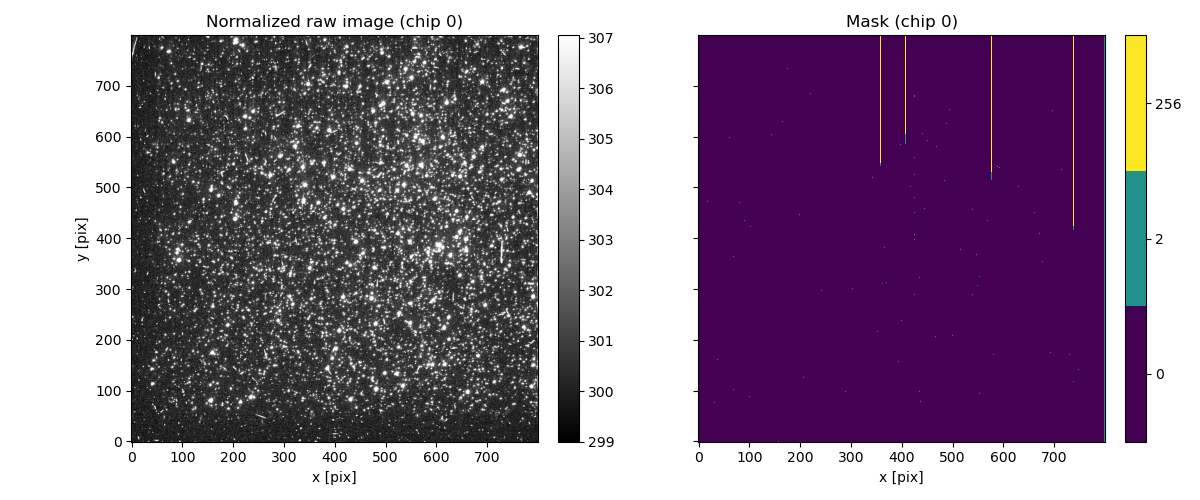

In [6]:
chip = 0  # 0-3 -> DETECTOR 1-4

raw_data = cal['raw']['data'][chip]
mask_data = cal['maskfile']['data'][chip]

raw_norm = ImageNormalize(raw_data, interval=ZScaleInterval())

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

im0 = axes[0].imshow(raw_data, origin='lower', cmap='gray', norm=raw_norm)
axes[0].set_title(f'Normalized raw image (chip {chip})')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

flag_values = [0, 2, 256]
mask_index = np.searchsorted(flag_values, mask_data)  # 0 -> 0, 2 -> 1, 256 -> 2

im1 = axes[1].imshow(mask_index, origin='lower', cmap=plt.get_cmap('viridis', 3),
                     vmin=-0.5, vmax=2.5, interpolation='nearest')
axes[1].set_title(f'Mask (chip {chip})')
cbar1 = fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, ticks=[0, 1, 2])
cbar1.ax.set_yticklabels([str(v) for v in flag_values])

for ax in axes:
    ax.set_xlabel('x [pix]')
axes[0].set_ylabel('y [pix]')

plt.tight_layout()
plt.show()

We can see that some streaks of questionable pixels appear on the image and at the tips of all these streaks, there are invalid pixels. Aside from this, there are several defective pixels scattered across the image, so I consider it necessary to apply the mask in the processing pipeline. I decide to keep the questionable pixels (identifying them) because upon closer inspection of the region, they do not seem to heavily affect the image. 

### 1.2. Apply and verify the mask is correctly applied (using the MASKFILE)
(defective in mask should be equal to NaN in result if we keep the questionable pixels)

In [7]:
masked, questionable = apply_mask(cal)

print("defective in mask:", np.sum(cal['maskfile']['data'] == 2))
print("NaN in result:    ", np.sum(np.isnan(masked)))
print("questionable kept:", np.sum(questionable))

defective in mask: 5430
NaN in result:     5430
questionable kept: 13378


### 1.3. Save the masked image 

In [8]:
save_fits(masked, cal['raw']['header'],
          here / "hst-processed" / f"{calibration_image}_masked.fits",
          history="MASKFILE applied: defective (2) set to NaN, questionable (256) kept")

## 2. Correct Analog-to-Digital conversion errors with ATODFILE
This step is skipped

## 3. Remove bias level with the BLEVFILE

In [9]:
bias_corrected, bias_levels = subtract_bias_level(masked, cal['blevfile']['data'])

for chip, (even, odd) in enumerate(bias_levels):
    print(f"chip {chip} (DETECTOR {chip + 1}): even {even:.4f}, odd {odd:.4f}")

c0m_hdr = fits.getheader(here / "hst-data" / cal['raw']['header']['FILTNAM1'].strip() / f"{calibration_image}_c0m_aligned.fits", 1)
print("pipeline (DETECTOR 1): BIASEVEN", c0m_hdr['BIASEVEN'], " BIASODD", c0m_hdr['BIASODD'])

print("NaN before:", np.sum(np.isnan(masked)), " after:", np.sum(np.isnan(bias_corrected)))

save_fits(bias_corrected, cal['raw']['header'],
          here / "hst-processed" / f"{calibration_image}_blev.fits",
          history="BLEVFILE applied: mean overscan bias level subtracted per chip, even/odd columns")

chip 0 (DETECTOR 1): even 299.5591, odd 299.5578
chip 1 (DETECTOR 2): even 319.9347, odd 319.9125
chip 2 (DETECTOR 3): even 313.4264, odd 313.4341
chip 3 (DETECTOR 4): even 297.5988, odd 297.6368
pipeline (DETECTOR 1): BIASEVEN 299.5152  BIASODD 299.5215
NaN before: 5430  after: 5430


If we compare our bias levels (chip 0) with the values from the aligned reference image we are comparing against, we can see that they are very similar, with the small differences likely due to the way this step calculations were defined in their respective pipelines. If we run the notebook for the three files that need calibration, we obtain similar values in all runs.

## 4. Get the header from the raw file and remove bias image with the BIASFILE
The header contains useful metadata that the functions use as inputs

In [10]:
raw_hdr = cal['raw']['header']

debiased = subtract_bias_image(bias_corrected, cal['biasfile']['data'])

## 5. Subtract the dark with the DARKFILE

In [11]:
dark_subtracted = subtract_dark(debiased, cal['darkfile']['data'],
                                dark_time=raw_hdr['DARKTIME'],
                                dark_ref_time=cal['darkfile']['header']['DARKTIME'])

## 6. Flatfield correction with FLATFILE

In [12]:
calibrated = apply_flat(dark_subtracted, cal['flatfile']['data'])

save_fits(calibrated, raw_hdr,
          here / "hst-processed" / f"{calibration_image}_calibrated.fits",
          history="BIASFILE subtracted, DARKFILE scaled by DARKTIME subtracted, FLATFILE (inverse flat) multiplied")

## 7. Remove shading with SHADFILE
This step is skipped

## 8. Photometry calibration with PHOTTAB

In [13]:
filter_name = raw_hdr['FILTNAM1'].strip()

phot_tables = {
    'F336W': {'PHOTMODE': 'WFPC2,1,A2D15,F336W,,CAL', 'PHOTFLAM': 1.115396e-16, 'PHOTZPT': -21.1,
              'PHOTPLAM': 3359.474, 'PHOTBW': 204.4908, 'ZP_CORR': -0.03288031},
    'F555W': {'PHOTMODE': 'WFPC2,1,A2D15,F555W,,CAL', 'PHOTFLAM': 6.920538e-18, 'PHOTZPT': -21.1,
              'PHOTPLAM': 5442.934, 'PHOTBW': 522.2513, 'ZP_CORR': 0.02655506},
}

phot = phot_tables[filter_name]
print("Filter:", filter_name, "->", phot['PHOTMODE'])

pipeline_path = here / "hst-data" / filter_name / f"{calibration_image}_c0m_aligned.fits"
pipeline_hdr = fits.getheader(pipeline_path, 1)
for key in ['PHOTFLAM', 'PHOTZPT', 'ZP_CORR']:
    print(f"{key:8} table {phot[key]:<12} c0m header {pipeline_hdr[key]:<12} "
          f"match {np.isclose(phot[key], pipeline_hdr[key])}")

phot_hdr = raw_hdr.copy()
for key, value in phot.items():
    phot_hdr[key] = value

flux = photometric_calibration(calibrated[0], raw_hdr['EXPTIME'], phot['PHOTFLAM'])

with np.errstate(invalid='ignore', divide='ignore'):
    mag = flux_to_mag(flux, phot['PHOTZPT'], phot['ZP_CORR'])

print("median flux:", np.nanmedian(flux), " brightest pixel (mag):", np.nanmin(mag))

save_fits(flux, phot_hdr,
          here / "hst-processed" / f"{calibration_image}_flux.fits",
          history=f"Photometry keywords for {filter_name} added; counts converted to flux density with PHOTFLAM / EXPTIME")

Filter: F336W -> WFPC2,1,A2D15,F336W,,CAL
PHOTFLAM table 1.115396e-16 c0m header 1.115396e-16 match True
PHOTZPT  table -21.1        c0m header -21.1        match True
ZP_CORR  table -0.03288031  c0m header -0.03288031  match True
median flux: 1.2783259245927137e-19  brightest pixel (mag): 14.81935079230362


## 9. Obtaining the corrected image, considering the sky contribution

In [14]:
sky_subtracted, sky, sky_noise = subtract_sky(calibrated)

for chip, (level, noise) in enumerate(zip(sky, sky_noise)):
    print(f"chip {chip} (DETECTOR {chip + 1}): sky {level:.4f} DN, MAD_STD {noise:.4f} DN, "
          f"median after subtraction {np.nanmedian(sky_subtracted[chip]):.4f} DN")

print("NaN before:", np.sum(np.isnan(calibrated)), " after:", np.sum(np.isnan(sky_subtracted)))

save_fits(sky_subtracted, raw_hdr,
          here / "hst-processed" / f"{calibration_image}_skysub.fits",
          history="Sky subtracted per chip: median after 3 sigma MAD_STD clipping")

skysub_flux = photometric_calibration(sky_subtracted[0], raw_hdr['EXPTIME'], phot['PHOTFLAM'])

save_fits(skysub_flux, phot_hdr,
          here / "hst-processed" / f"{calibration_image}_skysub_flux.fits",
          history="Sky subtracted chip 0 converted to flux density with PHOTFLAM / EXPTIME")

chip 0 (DETECTOR 1): sky 0.7781 DN, MAD_STD 1.0140 DN, median after subtraction 0.0241 DN
chip 1 (DETECTOR 2): sky -0.3572 DN, MAD_STD 0.0705 DN, median after subtraction 0.1049 DN
chip 2 (DETECTOR 3): sky 0.0341 DN, MAD_STD 0.0874 DN, median after subtraction 0.0699 DN
chip 3 (DETECTOR 4): sky 0.7322 DN, MAD_STD 0.9969 DN, median after subtraction 0.0320 DN
NaN before: 5430  after: 5430


The sky is estimated per chip as the median after 3σ clipping, which removes stars so only the background remains. For chip 0 this gives $\approx 0.78$ DN (noise $\approx 1.0$ DN). Chips 1 and 2 give unreliable values because they contain almost no signal, so most pixels sit near whole-number DN and the MAD collapses towards zero; this does not affect our chip 0 comparison.

## 10. Run the same calibration process for all files

In [15]:
results = {}

for image_id in sorted(p.name for p in calib_dir.iterdir() if p.is_dir()):
    result = calibrate_exposure(image_id, calib_dir, phot_tables)
    results[image_id] = result

    save_fits(result['calibrated'], result['header'],
              here / "hst-processed" / f"{image_id}_calibrated.fits",
              history="BIASFILE subtracted, DARKFILE scaled by DARKTIME subtracted, FLATFILE (inverse flat) multiplied")
    save_fits(result['sky_subtracted'], result['header'],
              here / "hst-processed" / f"{image_id}_skysub.fits",
              history="Sky subtracted per chip: median after 3 sigma MAD_STD clipping")
    save_fits(result['flux'], result['phot_header'],
              here / "hst-processed" / f"{image_id}_skysub_flux.fits",
              history="Sky subtracted chip 0 converted to flux density with PHOTFLAM / EXPTIME")

    print(image_id, result['filter'], "calibrated and saved")

1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


ubai2505m F336W calibrated and saved


1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


ubai2507m F336W calibrated and saved


1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


ubai2508m F336W calibrated and saved


# Compare and Contrast

## 11. Compare our calibrated image with the source of material

In [16]:
pipeline = fits.getdata(pipeline_path, 1)
print("Filter:", filter_name, " pipeline units:", pipeline_hdr.get('BUNIT'))

Filter: F336W  pipeline units: COUNTS


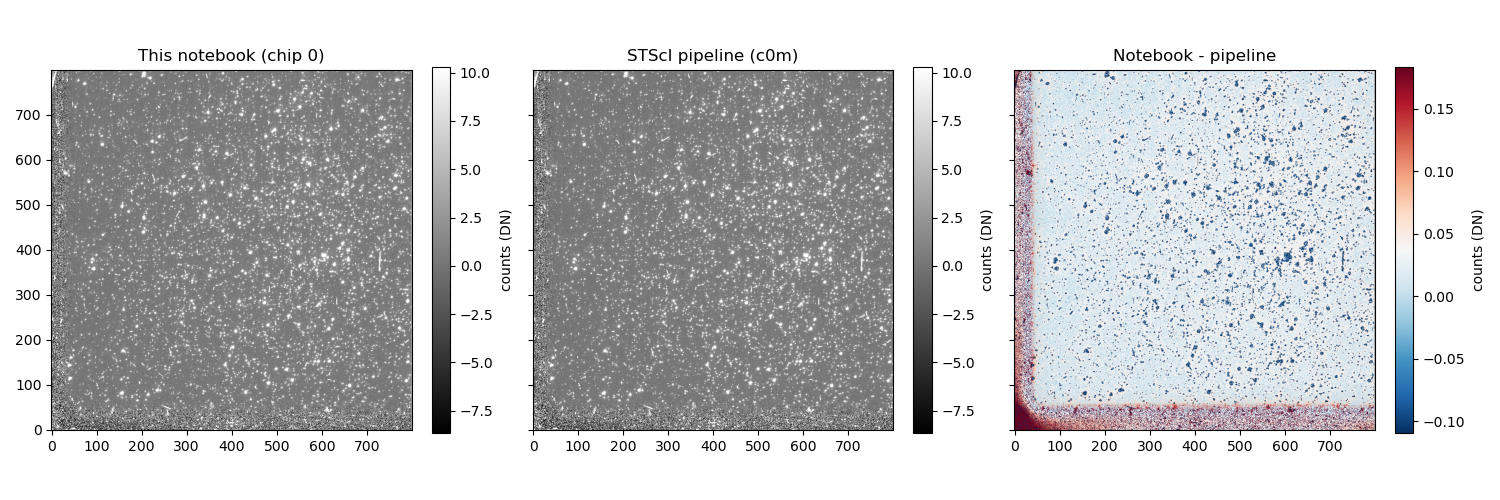

In [17]:
norm = ImageNormalize(pipeline, interval=ZScaleInterval())
difference = calibrated[0] - pipeline

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
panels = [(calibrated[0], 'This notebook (chip 0)', norm, 'gray'),
          (pipeline, 'STScI pipeline (c0m)', norm, 'gray'),
          (difference, 'Notebook - pipeline', ImageNormalize(difference, interval=ZScaleInterval()), 'RdBu_r')]

for ax, (image, title, image_norm, cmap) in zip(axes, panels):
    im = ax.imshow(image, origin='lower', cmap=cmap, norm=image_norm)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, label='counts (DN)')

plt.tight_layout()
plt.show()

We can see from the third plot that the differences between the two images mostly lie between about $-0.10$ and $0.20$ counts. These are the colour limits of the plot, which are chosen with a z-scale normalisation to show the background, so a few pixels fall outside them. For comparison, the colour scale of the two separate images covers about $-10$ to $10$ counts with the same normalisation. The differences are therefore about two orders of magnitude smaller than the variations within each image, and smaller than the sky noise in a single pixel ($\approx 1$ count). This indicates very good agreement between our calibrated image and the reference image, which we quantify further with a histogram of the pixel-by-pixel differences.

The remaining differences are not completely random. The left and bottom edges of the chip show a positive band, where our image is slightly brighter than the reference. This area receives less light and has the largest flat-field correction, so small differences in the bias and dark subtraction are amplified there. The background also has a small overall positive offset, consistent with our bias levels being $\approx 0.04$ counts higher than the pipeline's `BIASEVEN` and `BIASODD` values.

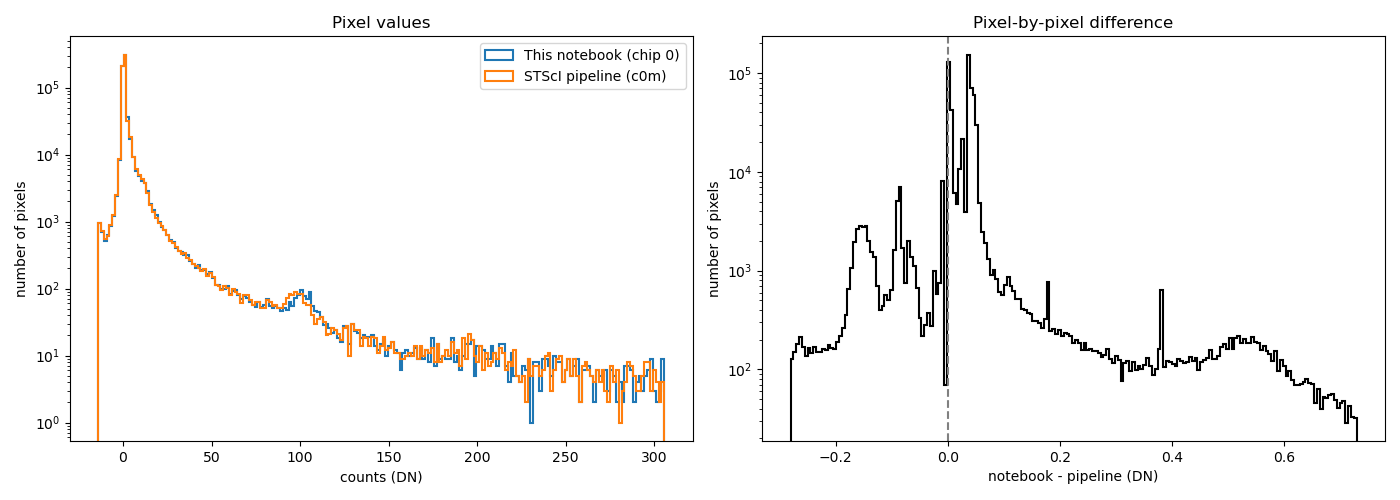

                    median       std    NaN
This notebook        0.802    82.909   1169
STScI pipeline       0.764    82.903      0
Difference           0.036     0.249
86.2% of pixels between 0 and 0.1 DN


In [21]:
mine = calibrated[0][np.isfinite(calibrated[0])]
theirs = pipeline[np.isfinite(pipeline)]
difference_values = difference[np.isfinite(difference)]

low, high = np.percentile(np.concatenate([mine, theirs]), [0.5, 99.9])
bins = np.linspace(low, high, 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(mine, bins=bins, histtype='step', lw=1.5, label='This notebook (chip 0)')
axes[0].hist(theirs, bins=bins, histtype='step', lw=1.5, label='STScI pipeline (c0m)')
axes[0].set_yscale('log')
axes[0].set_xlabel('counts (DN)')
axes[0].set_ylabel('number of pixels')
axes[0].set_title('Pixel values')
axes[0].legend()

diff_low, diff_high = np.percentile(difference_values, [0.5, 99.5])
axes[1].hist(difference_values, bins=np.linspace(diff_low, diff_high, 200), histtype='step', lw=1.5, color='k')
axes[1].axvline(0, color='gray', ls='--')
axes[1].set_yscale('log')
axes[1].set_xlabel('notebook - pipeline (DN)')
axes[1].set_ylabel('number of pixels')
axes[1].set_title('Pixel-by-pixel difference')

plt.tight_layout()
plt.show()

print(f"{'':16} {'median':>9} {'std':>9} {'NaN':>6}")
print(f"{'This notebook':16} {np.median(mine):9.3f} {np.std(mine):9.3f} {np.sum(np.isnan(calibrated[0])):6}")
print(f"{'STScI pipeline':16} {np.median(theirs):9.3f} {np.std(theirs):9.3f} {np.sum(np.isnan(pipeline)):6}")
print(f"{'Difference':16} {np.median(difference_values):9.3f} {np.std(difference_values):9.3f}")
print(f"{np.mean((difference_values >= 0) & (difference_values <= 0.1)):.1%} of pixels between 0 and 0.1 DN")

We can see that the two histograms of pixel values are almost identical. In the pixel-by-pixel difference, the majority of pixels (≈ 86.2%) lie between $0$ and $0.1$ DN, with a median of $0.036$ DN and a standard deviation of $0.25$ DN. Smaller groups of pixels appear around $-0.15$ and $-0.08$ DN, and a tail extends up to $\approx 0.7$ DN, which likely corresponds to the edge band seen in the difference image. See the next plot

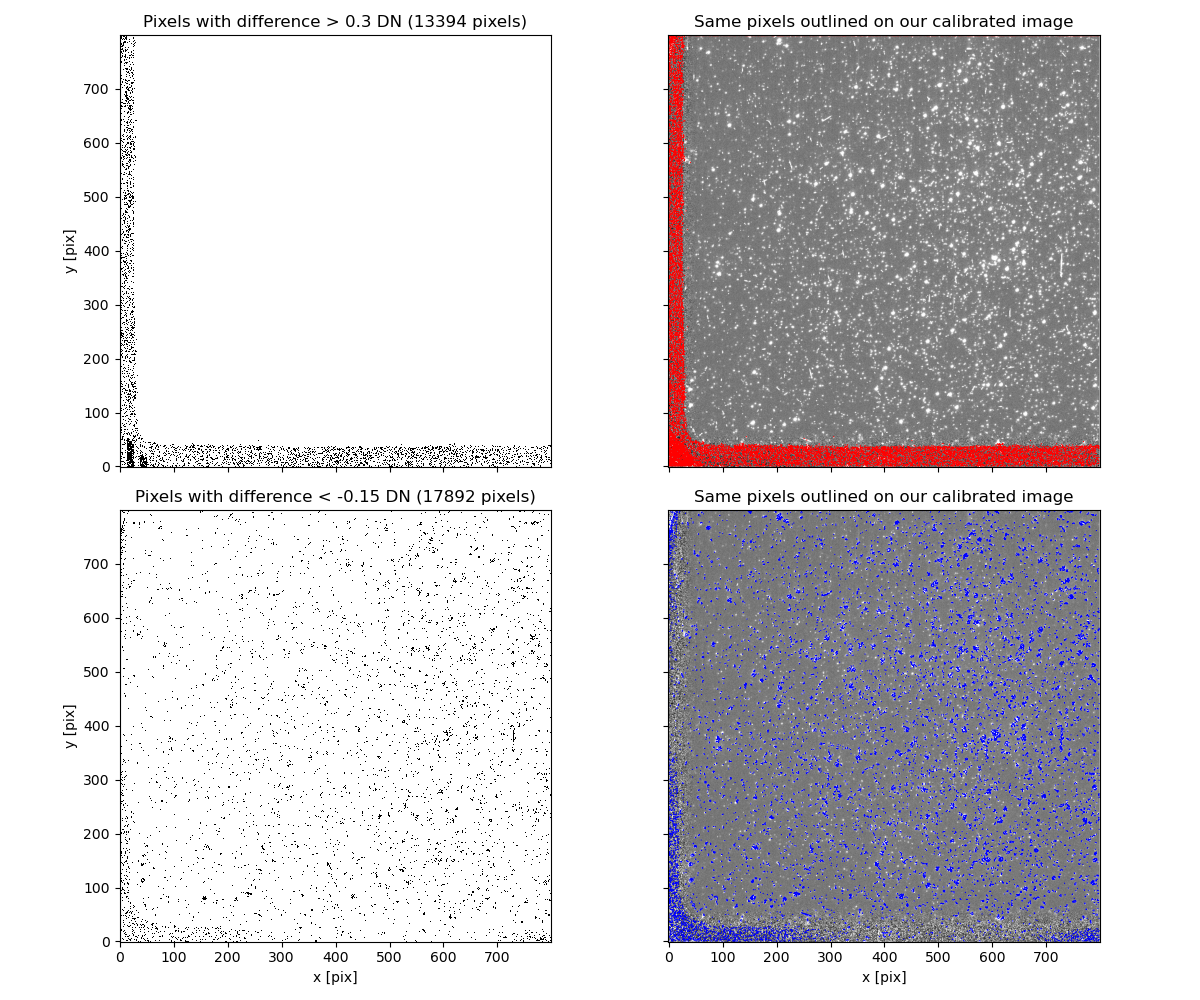

In [23]:
selections = [(difference > 0.3, 'difference > 0.3 DN', 'red'),
              (difference < -0.15, 'difference < -0.15 DN', 'blue')]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

for row, (selected, label, colour) in zip(axes, selections):
    row[0].imshow(selected, origin='lower', cmap='gray_r', interpolation='nearest')
    row[0].set_title(f'Pixels with {label} ({selected.sum()} pixels)')

    row[1].imshow(calibrated[0], origin='lower', cmap='gray', norm=norm)
    row[1].contour(selected, levels=[0.5], colors=colour, linewidths=0.5)
    row[1].set_title('Same pixels outlined on our calibrated image')

for ax in axes[1]:
    ax.set_xlabel('x [pix]')
for ax in axes[:, 0]:
    ax.set_ylabel('y [pix]')

plt.tight_layout()
plt.show()

Pixels above $0.3$ DN lie almost entirely in the edge band, while pixels below $-0.15$ DN are compact spots that appear to coincide with stars and other bright sources. The edge band is noisier in both directions, as it receives less light and has the largest flat-field correction.

## 12. Final results

In [19]:
print(f"{'image':10} {'filter':6} {'bias even':>9} {'BIASEVEN':>9} {'bias odd':>9} {'BIASODD':>9} "
      f"{'sky':>6} {'MAD_STD':>7} {'diff median':>11} {'diff std':>8} {'NaN':>5}")

for image_id, result in results.items():
    pipeline_file = here / "hst-data" / result['filter'] / f"{image_id}_c0m_aligned.fits"
    pipeline_file_hdr = fits.getheader(pipeline_file, 1)
    diff = result['calibrated'][0] - fits.getdata(pipeline_file, 1)
    diff = diff[np.isfinite(diff)]

    print(f"{image_id:10} {result['filter']:6} "
          f"{result['bias_levels'][0, 0]:9.4f} {pipeline_file_hdr['BIASEVEN']:9.4f} "
          f"{result['bias_levels'][0, 1]:9.4f} {pipeline_file_hdr['BIASODD']:9.4f} "
          f"{result['sky'][0]:6.3f} {result['sky_noise'][0]:7.3f} "
          f"{np.median(diff):11.4f} {np.std(diff):8.4f} {np.sum(np.isnan(result['calibrated'][0])):5}")

image      filter bias even  BIASEVEN  bias odd   BIASODD    sky MAD_STD diff median diff std   NaN
ubai2505m  F336W   299.5847  299.5152  299.5915  299.5215  0.739   1.037      0.0305   0.2176  1169
ubai2507m  F336W   299.5591  299.5152  299.5578  299.5215  0.778   1.014      0.0364   0.2487  1169
ubai2508m  F336W   299.6214  299.5152  299.6210  299.5215  0.786   1.022      0.0352   0.2793  1169


All three F336W exposures give consistent results. Our bias levels are $0.04$–$0.10$ DN higher than the pipeline's `BIASEVEN` and `BIASODD` values, which matches the small positive median difference ($0.03$–$0.04$ DN) between our images and the reference. The spread of the differences ($0.22$–$0.28$ DN) is well below the sky noise of $\approx 1$ DN in every exposure, so the calibrations agree to within the noise. The 1169 NaN pixels are the same in every exposure because they come from the static bad-pixel mask, which the pipeline does not set to NaN.

# AI usage

I used Claude (Anthropic, model Claude Opus 5.5) through the Claude Code desktop app on 22 and 24 October 2026. It could read the notebook and run Python in my `ccd_data` environment. In the first session Claude wrote or changed the code for the mask plot (Section 1.1), the photometry tables and flux/magnitude conversion (Section 8), the `subtract_sky` function (Section 9), the `calibrate_exposure` function and loop (Section 10), the comparison plots and summary table (Sections 11–12), and restructured the section headings. It also explained the mask, bias-level, photometry and sky-subtraction results, and checked the notebook against the assignment brief. In the second session Claude reviewed the notebook against the brief and guidance again, wrote the code for the plots of pixels with large positive and negative differences, completed or corrected the docstrings I had started for each function, and suggested wording for the markdown discussing the difference image, histogram and summary table, which I edited.

Claude also explained the units of the comparison plots (DN, gain, log-scaled histograms), why calibrated counts can be fractional or negative, what WFPC2 and its four chips are, why only chip 0 can be compared with the pipeline file, and what the edge band in the difference image corresponds to. 

Finally, Claude was also used to review the final version of the notebook and compare it to the assignment's requirements and rubric.